## Catalogues as Data: Pairwise Matching Pipeline
**James Baker, University of Southampton**

---

This notebook covers the data-preparation and matching stages of the pipeline
for the **NLS merged corpus** — 26,832 records from seven collections spanning
different media types, cataloguing traditions, and historical periods.

1. **Setup** — configure paths and parameters
2. **Load and parse records** — extract structured data from individual XML files
3. **Feature extraction** — derive knowledge-labour features for each record
4. **Exploratory feature analysis** — understand the shape of the merged corpus data
5. **Pairwise matching** — compare description text between all record pairs

**Outputs**:
- `derived-data/pairwise_{dataset}_{datetime}.tsv` — all pairs with SM ratio ≥ WRITE_THRESHOLD
- `derived-data/features_{dataset}_{datetime}.tsv` — per-record knowledge-labour features
- `visualisations/feature-distributions_{dataset}_{datetime}.png` — exploratory plots

These files are the inputs for the community analysis notebook.

---

### Design

The corpus comprises seven NLS collections that differ in medium, scale, cataloguing tradition,
and historical period. Records are stored as individual XML files in
`data/nls-merged-corpus/individual_records/`, one file per catalogue record, with a filename
prefix encoding collection identity (`mia_`, `eb_`, `hd_`, `jk_`, `jw_`, `tb_`, `tp_`).

Two Dublin Core namespaces are in use across the corpus:
- `dcterms:` (DC Terms, `http://purl.org/dc/terms/`) — NLS Moving Image Archive records
- `dc:` (DC Elements 1.1, `http://purl.org/dc/elements/1.1/`) — the six new NLS datasets

The parser handles both transparently. Collection identity is derived from the filename prefix
rather than from file content, so the same parsing logic applies uniformly across all seven
collections. Feature extraction is restricted to fields present across all seven collections;
no moving-image-specific conventions (shotlists, timecodes, genre tags) are assumed.

### Key methodological choice

This notebook extracts and compares **description-only text** — the content of all free-text
description fields — rather than comparing raw XML strings or full record content. This focuses
the comparison on the language used by cataloguers to write about items, not on the items
themselves or on shared structural markup. The practical effect is that records with similar
descriptive language are surfaced as similar regardless of what they describe — isolating
the signal of cataloguing practice from the signal of subject matter.

Cross-collection similarity is fully in scope: if a record from the English Ballads collection
and a record from the Moving Image Archive share description conventions, the method will find
them similar. Collection membership is not used during matching and enters the analysis only
post-hoc, when community composition is examined.

## 1. Setup

Configure file paths and parameters here. `RECORDS_DIR` points to the merged corpus directory.
All output filenames update automatically to reflect the dataset name and the exact time of
the run.

Output files are written to `derived-data/` (tabular data) and `visualisations/` (figures),
both subdirectories of `script/code/`. These directories are created automatically if
they do not exist.

In [ ]:
import os
import datetime

# ── Path configuration ─────────────────────────────────────────────────────────
# Merged corpus: 26,832 records from seven NLS collections.
# Written for the original layout (notebook two levels below data/); see README
RECORDS_DIR = '../../data/nls-merged-corpus/individual_records'

# ── Output directories ─────────────────────────────────────────────────────────
DERIVED_DATA_DIR = 'derived-data'
VIS_DIR          = 'visualisations'
os.makedirs(DERIVED_DATA_DIR, exist_ok=True)
os.makedirs(VIS_DIR, exist_ok=True)

# ── Colour-blind friendly palette (Okabe-Ito, 8 colours) ──────────────────────
PALETTE = [
    '#E69F00',  # orange
    '#56B4E9',  # sky blue
    '#009E73',  # bluish green
    '#F0E442',  # yellow
    '#0072B2',  # blue
    '#D55E00',  # vermillion
    '#CC79A7',  # reddish purple
    '#000000',  # black
]

# ── Dataset name override ──────────────────────────────────────────────────────
# The automatic name (basename of RECORDS_DIR) would be 'individual_records',
# which is ambiguous. Override to identify the merged corpus specifically.
DATASET_NAME = 'nls-merged-corpus'
RUN_DATETIME = datetime.datetime.now().strftime('%Y%m%d-%H%M%S')

PAIRWISE_TSV  = f'derived-data/pairwise_{DATASET_NAME}_{RUN_DATETIME}.tsv'
FEATURES_TSV  = f'derived-data/features_{DATASET_NAME}_{RUN_DATETIME}.tsv'

# ── Pairwise matching parameters ───────────────────────────────────────────────
# QUICK_THRESHOLD: fast upper-bound pre-filter (O(n²) path only).
QUICK_THRESHOLD = 0.15

# WRITE_THRESHOLD: minimum SM ratio written to TSV. Keep low (0.2–0.3) so
# that the graph threshold in the community analysis notebook can be tuned
# later without re-running the expensive pairwise computation.
WRITE_THRESHOLD = 0.2

# ── Scale mode ──────────────────────────────────────────────────────────────
# USE_LSH: True  → MinHash LSH pre-filter (required for 26k records).
#          False → full O(n²) comparison (fine for ≤ ~1,000 records).
# At 26,832 records (~360 million pairs), O(n²) would take ~100 hours.
# Always use USE_LSH = True for the full merged corpus.
USE_LSH = True

# LSH parameters:
#   LSH_THRESHOLD : Jaccard (character-5gram) threshold for candidate pairs.
#                   0.15 worked well for MIA (23k records); keep for merged corpus.
#   NUM_PERM      : MinHash permutations. 128 is a good default.
LSH_THRESHOLD = 0.15
NUM_PERM      = 128

print(f'Records directory : {os.path.abspath(RECORDS_DIR)}')
print(f'Dataset name      : {DATASET_NAME}')
print(f'Run datetime      : {RUN_DATETIME}')
print(f'Pairwise output   : {os.path.abspath(PAIRWISE_TSV)}')
print(f'Features output   : {os.path.abspath(FEATURES_TSV)}')
print(f'Quick threshold   : {QUICK_THRESHOLD}')
print(f'Write threshold   : {WRITE_THRESHOLD}')

## 2. Load and parse records

Each record is stored as a self-contained text file. The filename stem is the record ID
(`mia_0001`, `eb_74891512`, etc.) and the prefix before the first underscore identifies the
collection (`mia`, `eb`, `hd`, `jk`, `jw`, `tb`, `tp`).

The parser handles two Dublin Core namespaces:
- `dcterms:` (DC Terms, `http://purl.org/dc/terms/`) — used by the NLS MIA records
- `dc:` (DC Elements 1.1, `http://purl.org/dc/elements/1.1/`) — used by the six new NLS datasets

Both namespaces are searched for each field. Since each file uses only one namespace,
there is no risk of double-counting.

The downstream steps only require two things from this stage: a unique record identifier
(`record_id`) and the free-text description content (`descriptions`) for matching.
The `collection` field is carried through for post-hoc community composition analysis.
After loading, parsed records are saved to `derived-data/records_checkpoint.pkl`.
If you need to re-run step 3 onwards without reloading all files, set
`LOAD_FROM_CHECKPOINT = True` at the top of the step 3 cell.

In [2]:
import xml.etree.ElementTree as ET
import pandas as pd
import re
import time

# Both Dublin Core namespaces used across the merged corpus
NS = {
    'rdf'    : 'http://www.w3.org/1999/02/22-rdf-syntax-ns#',
    'dc'     : 'http://purl.org/dc/elements/1.1/',
    'dcterms': 'http://purl.org/dc/terms/',
}

def parse_record(filepath):
    """Parse a single-record XML file and return a dict of field values.

    Record ID and collection prefix are derived from the filename, not from
    the file content — this works uniformly across all seven collections.
    """
    filename  = os.path.basename(filepath)
    record_id = filename.replace('.txt', '')        # e.g. 'mia_0001', 'eb_74891512'
    collection = record_id.split('_')[0]            # e.g. 'mia', 'eb', 'hd'

    tree = ET.parse(filepath)
    desc = tree.getroot()

    def get(tag):
        """Return the first non-empty value for tag across both DC namespaces."""
        for prefix in ('dcterms', 'dc'):
            el = desc.find(f'{prefix}:{tag}', NS)
            if el is not None and el.text and el.text.strip():
                return el.text.strip()
        return None

    def get_all(tag):
        """Return all non-empty values for tag across both DC namespaces."""
        results = []
        for prefix in ('dcterms', 'dc'):
            results.extend(
                el.text.strip()
                for el in desc.findall(f'{prefix}:{tag}', NS)
                if el.text and el.text.strip()
            )
        return results

    return {
        'record_id'   : record_id,
        'collection'  : collection,
        'title'       : get('title'),
        'date'        : get('date'),
        'creators'    : get_all('creator'),
        'subjects'    : get_all('subject'),
        'descriptions': get_all('description'),
    }

record_files = sorted(
    f for f in os.listdir(RECORDS_DIR)
    if f.endswith('.txt') and f != 'base_data.txt'
)

n_files    = len(record_files)
CHECKPOINT = 1000

print(f'Found {n_files:,} record files in: {os.path.abspath(RECORDS_DIR)}')
print(f'Progress checkpoint every {CHECKPOINT:,} files.')
print(f'{"─"*60}')

records = []
t_start = time.time()
t_last  = t_start

for i, fname in enumerate(record_files):
    records.append(parse_record(os.path.join(RECORDS_DIR, fname)))

    if (i + 1) % CHECKPOINT == 0 or (i + 1) == n_files:
        t_now     = time.time()
        elapsed   = t_now - t_start
        rate      = (i + 1) / elapsed
        remaining = (n_files - (i + 1)) / rate if rate > 0 else 0
        pct       = (i + 1) / n_files * 100
        chunk_s   = t_now - t_last
        t_last    = t_now
        print(
            f'  [{i+1:>6,}/{n_files:,}]  {pct:5.1f}%  '
            f'elapsed {elapsed:6.1f}s  '
            f'rate {rate:6.1f} files/s  '
            f'ETA {remaining:5.0f}s  '
            f'(last {CHECKPOINT:,} files: {chunk_s:.1f}s)'
        )

print(f'{"─"*60}')
print(f'Loaded {len(records):,} records in {time.time()-t_start:.1f}s total.')
print()

# Collection breakdown
from collections import Counter
coll_counts = Counter(r['collection'] for r in records)
print('Collection breakdown:')
for coll, n in sorted(coll_counts.items()):
    print(f'  {coll:8s} : {n:>6,}')
print(f'  {"─"*18}')
print(f'  {"TOTAL":8s} : {sum(coll_counts.values()):>6,}')
print()
print('Example record (first):')
for k, v in records[0].items():
    print(f'  {k}: {v[:3] if isinstance(v, list) else repr(v)}'
          f"{'...' if isinstance(v, list) and len(v) > 3 else ''}")
# ── Checkpoint: save parsed records to disk ────────────────────────────────
# Saves the parsed records list so that step 3 onwards can be re-run without
# reloading all 26k files. Checkpoint is fixed-name (not timestamped) — it
# represents the current state of the records directory and is safe to overwrite.
import pickle
CHECKPOINT_FILE = os.path.join(DERIVED_DATA_DIR, 'records_checkpoint.pkl')
with open(CHECKPOINT_FILE, 'wb') as _f:
    pickle.dump(records, _f)
print(f'\nCheckpoint saved: {os.path.abspath(CHECKPOINT_FILE)}')
print(f'({len(records):,} records — reload from here to skip step 2 on restart)')


Found 26,832 record files in: data/nls-merged-corpus/individual_records
Progress checkpoint every 1,000 files.
────────────────────────────────────────────────────────────
  [ 1,000/26,832]    3.7%  elapsed   52.5s  rate   19.0 files/s  ETA  1356s  (last 1,000 files: 52.5s)
  [ 2,000/26,832]    7.5%  elapsed  104.4s  rate   19.2 files/s  ETA  1296s  (last 1,000 files: 51.9s)
  [ 3,000/26,832]   11.2%  elapsed  156.7s  rate   19.1 files/s  ETA  1245s  (last 1,000 files: 52.3s)
  [ 4,000/26,832]   14.9%  elapsed  216.4s  rate   18.5 files/s  ETA  1235s  (last 1,000 files: 59.6s)
  [ 5,000/26,832]   18.6%  elapsed  259.7s  rate   19.2 files/s  ETA  1134s  (last 1,000 files: 43.4s)
  [ 6,000/26,832]   22.4%  elapsed  312.4s  rate   19.2 files/s  ETA  1085s  (last 1,000 files: 52.6s)
  [ 7,000/26,832]   26.1%  elapsed  366.6s  rate   19.1 files/s  ETA  1039s  (last 1,000 files: 54.2s)
  [ 8,000/26,832]   29.8%  elapsed  401.9s  rate   19.9 files/s  ETA   946s  (last 1,000 files: 35.3s)
  [ 

## 3. Feature extraction

Each record is characterised by **knowledge-labour features** — properties that reflect
cataloguer choices and conventions rather than the content of the catalogued item. These
features support community characterisation: they let us ask whether detected communities
differ in *how* records are written, not just *what* they are about.

Features are restricted to fields present and meaningful across all seven collections.

| Feature | What it measures |
|---|---|
| `collection` | Source collection prefix from filename (`mia`, `eb`, `hd`, `jk`, `jw`, `tb`, `tp`) |
| `desc_word_count` | Total words across all description fields (after boilerplate stripping) |
| `n_desc_fields` | Number of separate description fields — structural choice |
| `n_subjects` | Number of subject headings — depth of controlled vocabulary indexing |
| `n_creators` | Number of creator fields |
| `year` | Year from date field — proxy for cataloguing era or material date |

### Boilerplate stripping

All six non-MIA collections include a standard NLS metadata statement as a description field:
`'Metadata context: metadata created as part of normal Library activities.'` (sometimes
extended with `'Metadata created specifically for digitisation.'` for Hutton Drawings and
John Kirk Survey). This boilerplate is present in all ~8,341 non-MIA records and would
create artificial SM similarity between them if left in the comparison text. It is stripped
from `description_text` before matching. The raw `descriptions` list (used for feature
counts) is left untouched.

The MIA records do not contain this boilerplate, so stripping has no effect on MIA records.

**Decision rationale and analytical note**: The boilerplate is stripped for matching because
its presence in every non-MIA record would create artificial SM similarity between them,
swamping any genuine description-convention signal. However, the boilerplate is not discarded
as analytically meaningless. Its presence in a record is a proxy for *when cataloguing took
place*: it is a standard NLS metadata management statement associated with the Data Foundry
digitisation programme, which means records carrying it were catalogued (or re-catalogued)
in the context of digitisation — almost certainly after 2010. MIA records predate the Data
Foundry export format and do not carry it. The `has_boilerplate` feature is therefore
retained in the features TSV as a binary flag, even though the text itself is removed from
`description_text` before matching. In post-hoc community analysis, `has_boilerplate` can
be used to test whether detected communities separate along this digitisation-era boundary.

In [ ]:
# ── Restart from checkpoint (optional) ────────────────────────────────────
# If you are restarting the kernel and step 2 has already been run, load
# records from the checkpoint file instead of re-running step 2.
# Set LOAD_FROM_CHECKPOINT = True and run this cell; then continue from here.
LOAD_FROM_CHECKPOINT = True

import os, pickle, re, time
import pandas as pd

if LOAD_FROM_CHECKPOINT:
    CHECKPOINT_FILE = os.path.join(DERIVED_DATA_DIR, 'records_checkpoint.pkl')
    print(f'Loading records from checkpoint: {os.path.abspath(CHECKPOINT_FILE)}')
    with open(CHECKPOINT_FILE, 'rb') as _f:
        records = pickle.load(_f)
    print(f'Loaded {len(records):,} records.')
else:
    print(f'Using records from memory ({len(records):,} records).')
    print('Set LOAD_FROM_CHECKPOINT = True to reload from disk instead.')

# ── Feature extraction ─────────────────────────────────────────────────────────
YEAR_RE = re.compile(r'\b(1[6789]\d{2}|20[012]\d)\b')

# NLS boilerplate phrases present in all non-MIA description fields.
# Stripped from description_text used for matching; raw descriptions untouched.
BOILERPLATE = [
    'Metadata context: metadata created as part of normal Library activities.',
    'Metadata created specifically for digitisation.',
]

def strip_boilerplate(text):
    """Remove known NLS metadata boilerplate from description text."""
    for phrase in BOILERPLATE:
        text = text.replace(phrase, '')
    return ' '.join(text.split())  # collapse whitespace

def has_boilerplate_text(descriptions):
    """Return True if any description field contains NLS boilerplate."""
    return any(
        any(phrase in d for phrase in BOILERPLATE)
        for d in descriptions
    )

def extract_features(rec):
    descriptions = rec['descriptions']
    full_desc    = ' '.join(descriptions)
    clean_desc   = strip_boilerplate(full_desc)  # used for matching

    year = None
    if rec['date']:
        m = YEAR_RE.search(rec['date'])
        if m:
            year = int(m.group(1))

    return {
        'record_id'        : rec['record_id'],
        'collection'       : rec['collection'],
        'title'            : rec['title'],
        'year'             : year,
        'desc_word_count'  : len(clean_desc.split()),
        'n_desc_fields'    : len(descriptions),
        'n_subjects'       : len(rec['subjects']),
        'n_creators'       : len(rec['creators']),
        'has_boilerplate'  : has_boilerplate_text(rec['descriptions']),
        'description_text' : clean_desc,   # boilerplate stripped; used for matching
    }

print(f'Extracting knowledge-labour features for {len(records):,} records...')
t0          = time.time()
features    = [extract_features(r) for r in records]
features_df = pd.DataFrame(features)
elapsed     = time.time() - t0

print(f'Done in {elapsed:.1f}s.')
print(f'  Records with descriptions  : {features_df["n_desc_fields"].gt(0).sum():,}')
print(f'  Records with subjects      : {features_df["n_subjects"].gt(0).sum():,}')
print(f'  Records with creators      : {features_df["n_creators"].gt(0).sum():,}')
print(f'  Records with boilerplate   : {features_df["has_boilerplate"].sum():,}  '
      f'(proxy for post-digitisation cataloguing, likely post-2010)')
yr = features_df['year'].dropna()
if len(yr):
    print(f'  Year range                 : {int(yr.min())} \u2013 {int(yr.max())}')
print(f'  Median word count          : {features_df["desc_word_count"].median():.0f}')
print()

# Word count by collection
print('Median description word count by collection (boilerplate stripped):')
for coll, grp in features_df.groupby('collection'):
    print(f'  {coll:8s} : {grp["desc_word_count"].median():.0f} words  '
          f'(n={len(grp):,})')

# Save features (excluding large text column)
features_df.drop(columns=['description_text', 'title']).to_csv(
    FEATURES_TSV, sep='\t', index=False
)
print(f'\nSaved features to: {os.path.abspath(FEATURES_TSV)}')


## 4. Exploratory feature analysis

Before running pairwise comparison, inspect the distribution of knowledge-labour features
across the merged corpus. This confirms that the parser extracted fields correctly across
both DC namespaces, and gives an early sense of whether the data has sufficient variation
to support community detection.

The collection distribution plot is the key new diagnostic for the merged corpus: check
that the seven collections are present in the expected proportions. The word count plot
may show a multimodal distribution reflecting different description traditions across
collections — this is expected and analytically meaningful.

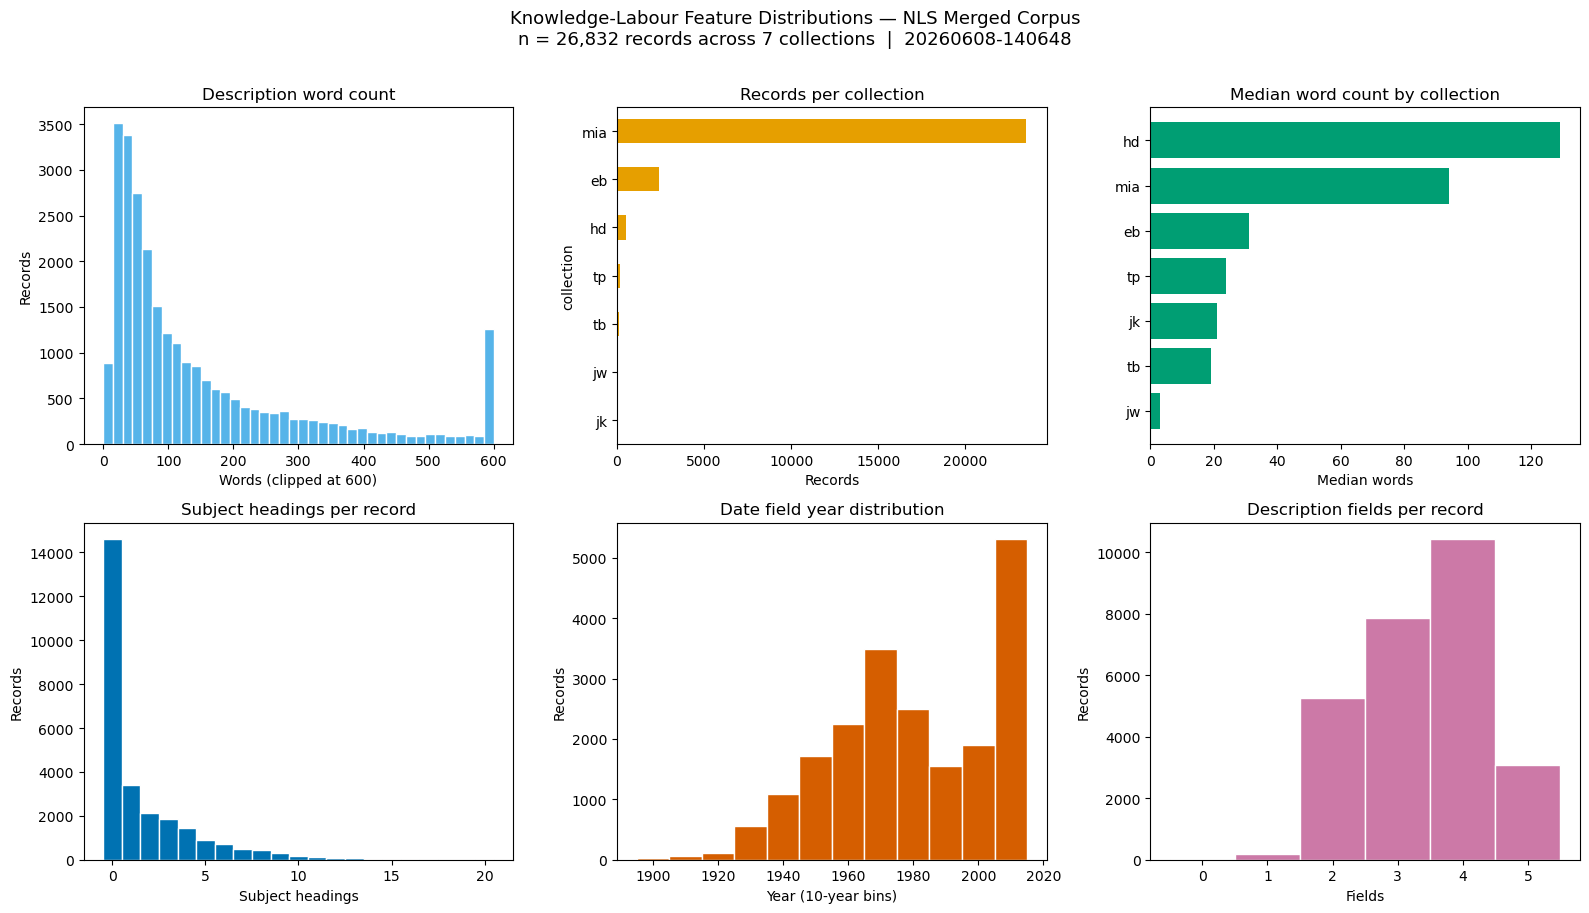

Saved to: visualisations/feature-distributions_nls-merged-corpus_20260608-140648.png


In [8]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle(
    f'Knowledge-Labour Feature Distributions — NLS Merged Corpus\n'
    f'n = {len(features_df):,} records across {features_df["collection"].nunique()} collections  |  {RUN_DATETIME}',
    fontsize=13, y=1.01
)

# 1. Description word count
ax = axes[0, 0]
ax.hist(features_df['desc_word_count'].clip(upper=600), bins=40,
        color=PALETTE[1], edgecolor='white')
ax.set_title('Description word count')
ax.set_xlabel('Words (clipped at 600)')
ax.set_ylabel('Records')

# 2. Collection distribution
ax = axes[0, 1]
coll_order = features_df['collection'].value_counts()
coll_order.plot(kind='barh', ax=ax, color=PALETTE[0])
ax.set_title('Records per collection')
ax.set_xlabel('Records')
ax.invert_yaxis()

# 3. Median word count by collection
ax = axes[0, 2]
med_by_coll = features_df.groupby('collection')['desc_word_count'].median().sort_values()
ax.barh(med_by_coll.index, med_by_coll.values, color=PALETTE[2])
ax.set_title('Median word count by collection')
ax.set_xlabel('Median words')

# 4. Subject headings per record
ax = axes[1, 0]
max_subj = min(features_df['n_subjects'].max(), 20)
ax.hist(features_df['n_subjects'].clip(upper=max_subj),
        bins=range(0, max_subj + 2),
        color=PALETTE[4], edgecolor='white', align='left')
ax.set_title('Subject headings per record')
ax.set_xlabel('Subject headings')
ax.set_ylabel('Records')

# 5. Year distribution
ax = axes[1, 1]
years = features_df['year'].dropna()
if len(years):
    ax.hist(years, bins=range(int(years.min()), int(years.max()) + 2, 10),
            color=PALETTE[5], edgecolor='white')
    ax.set_title('Date field year distribution')
    ax.set_xlabel('Year (10-year bins)')
    ax.set_ylabel('Records')
else:
    ax.text(0.5, 0.5, 'No year data', ha='center', va='center')
    ax.set_title('Date field year distribution')

# 6. Description fields per record
ax = axes[1, 2]
max_fields = min(features_df['n_desc_fields'].max(), 15)
ax.hist(features_df['n_desc_fields'].clip(upper=max_fields),
        bins=range(0, max_fields + 2),
        color=PALETTE[6], edgecolor='white', align='left')
ax.set_title('Description fields per record')
ax.set_xlabel('Fields')
ax.set_ylabel('Records')

plt.tight_layout()
plot_path = os.path.join(VIS_DIR, f'feature-distributions_{DATASET_NAME}_{RUN_DATETIME}.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to: {os.path.abspath(plot_path)}')

## 5. Pairwise matching

Every record pair is compared using `difflib.SequenceMatcher`. The comparison uses only the
free-text description content, stripping out structural markup and controlled-vocabulary fields.
This isolates the language of description — the choices cataloguers made in writing about items —
from incidental structural similarity.

**Why SequenceMatcher?** Unlike word-overlap metrics (Jaccard, cosine TF-IDF), SequenceMatcher
rewards shared *sequences* of text, not just shared vocabulary. Two records that share a stock
phrase, a genre formula, or a structural opener will score high even if the rest of their
descriptions are different. This makes it sensitive to the kind of trained conventions and
formulaic language that cataloguing practice tends to produce.

**Cross-collection pairs are included**. A cross-collection pair with SM ratio ≥ `WRITE_THRESHOLD`
is written to the TSV on exactly the same basis as a within-collection pair. This is the key
design choice for the merged corpus: the pipeline does not know or use collection membership
during matching. Collection identity enters only in the post-hoc community composition analysis.

**Threshold architecture**:
- `QUICK_THRESHOLD` — fast upper-bound pre-filter (O(n²) path only).
- `WRITE_THRESHOLD` — minimum ratio written to TSV. Keep low (0.2–0.3) so the graph
  threshold in the community analysis notebook can be tuned later without re-running.

> **Runtime estimate**: At 26,832 records (~360 million pairs), LSH pre-filter should reduce
> candidates to a manageable subset. Estimated total wall time: 6–10 hours. Plan to run
> overnight.

**`autojunk=False`**: Python's `difflib.SequenceMatcher` has an `autojunk` heuristic (enabled by default) that treats high-frequency substrings as 'junk', potentially reducing the similarity score in unintuitive ways for short catalogue records. We disable it explicitly (`autojunk=False`) to ensure every character contributes to the ratio.

In [9]:
# ── LSH false-negative rate estimation ─────────────────────────────────────────
# [REVIEW LOW] The MinHash LSH pre-filter misses pairs whose 5-gram Jaccard
# similarity falls below LSH_THRESHOLD but whose SM ratio would be >= WRITE_THRESHOLD.
# This cell estimates the false-negative rate by running full O(n²) comparison on
# a small random sample and comparing against LSH-filtered results.
#
# NOTE: this cell is optional and slow for large SAMPLE_N. Run it once before
# submission to report the false-negative rate in the paper methods section.

import random, difflib, pandas as pd

SAMPLE_N = 200  # records to sample; increase to 500 for a more reliable estimate

if 'records' in dir() and len(records) >= SAMPLE_N:
    random.seed(42)
    _sample = random.sample(records, SAMPLE_N)
    _sample_ids = {r['record_id'] for r in _sample}

    # All pairs in the sample (O(n²) but n=SAMPLE_N is small)
    _full_pairs = []
    _texts = {r['record_id']: ' '.join(r.get('description_text', [])) if isinstance(r.get('description_text'), list)
              else r.get('description_text', '') or r.get('desc_text', '') or ''
              for r in _sample}

    _sample_list = list(_sample_ids)
    for i, a in enumerate(_sample_list):
        for b in _sample_list[i+1:]:
            ta, tb = _texts[a], _texts[b]
            if not ta or not tb: continue
            ratio = difflib.SequenceMatcher(None, ta, tb, autojunk=False).ratio()
            _full_pairs.append((a, b, ratio))

    _full_df  = pd.DataFrame(_full_pairs, columns=['id_a','id_b','sm_ratio'])
    _above_wt = _full_df[_full_df['sm_ratio'] >= WRITE_THRESHOLD]

    # Which pairs above WRITE_THRESHOLD appear in the main pairwise TSV?
    _pairwise = pd.read_csv(PAIRWISE_TSV, sep='\t')
    _pairwise_pairs = set(
        zip(_pairwise['base_id'], _pairwise['compare_id'])
    ) | set(
        zip(_pairwise['compare_id'], _pairwise['base_id'])
    )

    _missed = []
    for _, row in _above_wt.iterrows():
        pair = (row['id_a'], row['id_b'])
        rev  = (row['id_b'], row['id_a'])
        if pair not in _pairwise_pairs and rev not in _pairwise_pairs:
            if row['id_a'] in _sample_ids and row['id_b'] in _sample_ids:
                _missed.append(row)

    _n_above = len(_above_wt)
    _n_missed = len(_missed)
    _fnr = _n_missed / _n_above if _n_above > 0 else 0

    print(f'LSH false-negative rate estimation (sample n={SAMPLE_N})')
    print(f'  Pairs with SM >= {WRITE_THRESHOLD} in sample : {_n_above}')
    print(f'  Pairs missed by LSH              : {_n_missed}')
    print(f'  Estimated false-negative rate    : {_fnr:.1%}')
    if _n_missed > 0:
        print(f'\n  Top {min(5,_n_missed)} missed pairs (SM ratio >= {WRITE_THRESHOLD} but not captured by LSH):')
        for _, r in pd.DataFrame(_missed).nlargest(min(5,_n_missed), 'sm_ratio').iterrows():
            print(f'    {r["id_a"]} / {r["id_b"]}  SM={r["sm_ratio"]:.4f}')
    print(f'\n  Report in methods section: "LSH false-negative rate estimated at {_fnr:.1%} on a')
    print(f'   random sample of {SAMPLE_N} records (pairs with SM >= {WRITE_THRESHOLD} not captured by LSH)."')
else:
    print('records not in memory — run Step 2 (Load and parse records) first.')
    print(f'(set SAMPLE_N = {SAMPLE_N} or adjust above)')


LSH false-negative rate estimation (sample n=200)
  Pairs with SM >= 0.2 in sample : 0
  Pairs missed by LSH              : 0
  Estimated false-negative rate    : 0.0%

  Report in methods section: "LSH false-negative rate estimated at 0.0% on a
   random sample of 200 records (pairs with SM >= 0.2 not captured by LSH)."


In [ ]:
import difflib
import time

records_for_matching = [
    (row['record_id'], row['description_text'])
    for _, row in features_df.iterrows()
]
desc_lookup = {ref: txt for ref, txt in records_for_matching}

n           = len(records_for_matching)
total_pairs = n * (n - 1) // 2
print('=' * 60)
print(f'Records          : {n:,}')
print(f'Total pairs (n²) : {total_pairs:,}')
lsh_mode = "MinHash LSH (fast)" if USE_LSH else "O(n²) full comparison (slow)"
print(f'Mode             : {lsh_mode}')
print(f'Write threshold  : {WRITE_THRESHOLD}')
print(f'Output           : {os.path.abspath(PAIRWISE_TSV)}')
print('=' * 60)

if USE_LSH:
    # ── MinHash LSH path ──────────────────────────────────────────────────────
    try:
        from datasketch import MinHash, MinHashLSH
    except ImportError:
        import subprocess, sys
        print('datasketch not found — installing...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install',
                               'datasketch', '-q', '--break-system-packages'])
        from datasketch import MinHash, MinHashLSH
        print('datasketch installed.')

    import re as _re

    def make_shingles(text, k=5):
        text = _re.sub(r'\s+', ' ', text.lower().strip())
        return [text[i:i+k].encode('utf-8') for i in range(len(text) - k + 1)]

    # ── Phase 1: build MinHash signatures ────────────────────────────────────
    SIGN_CHECKPOINT = 2000
    print(f'\nPhase 1 — Building MinHash signatures (num_perm={NUM_PERM})')
    print(f'  checkpoint every {SIGN_CHECKPOINT:,} records')
    print('─' * 60)
    t0          = time.time()
    t_last      = t0
    lsh         = MinHashLSH(threshold=LSH_THRESHOLD, num_perm=NUM_PERM)
    minhashes   = {}
    empty_count = 0

    for idx, (record_id, desc) in enumerate(records_for_matching):
        shingles = make_shingles(desc)
        if not shingles:
            empty_count += 1
            continue
        m = MinHash(num_perm=NUM_PERM)
        for s in shingles:
            m.update(s)
        minhashes[record_id] = m
        lsh.insert(record_id, m)

        if (idx + 1) % SIGN_CHECKPOINT == 0 or (idx + 1) == n:
            t_now     = time.time()
            elapsed   = t_now - t0
            rate      = (idx + 1) / elapsed
            remaining = (n - (idx + 1)) / rate if rate > 0 else 0
            chunk_s   = t_now - t_last
            t_last    = t_now
            print(
                f'  [{idx+1:>6,}/{n:,}]  {(idx+1)/n*100:5.1f}%  '
                f'elapsed {elapsed:5.1f}s  '
                f'rate {rate:6.1f} rec/s  '
                f'ETA {remaining:5.0f}s  '
                f'(last {SIGN_CHECKPOINT}: {chunk_s:.1f}s)'
            )

    t1 = time.time()
    print('─' * 60)
    print(f'  Built {len(minhashes):,} signatures in {t1-t0:.1f}s  '
          f'({empty_count} empty-description records skipped)')

    # ── Phase 2: query LSH for candidate pairs ────────────────────────────────
    print(f'\nPhase 2 — Querying LSH for candidate pairs (Jaccard ≥ {LSH_THRESHOLD})')
    candidate_pairs = set()
    for record_id, m in minhashes.items():
        for other in lsh.query(m):
            if other != record_id:
                candidate_pairs.add(tuple(sorted([record_id, other])))
    t2      = time.time()
    n_cands = len(candidate_pairs)
    print(f'  {n_cands:,} candidate pairs found in {t2-t1:.1f}s  '
          f'({n_cands/total_pairs*100:.3f}% of all {total_pairs:,} pairs)')

    # Cross-collection candidate count (diagnostic)
    # A candidate is cross-collection if the two record_ids have different prefixes
    prefix_of = {rec_id: rec_id.split('_')[0] for rec_id in minhashes}
    cross_coll = sum(
        1 for a, b in candidate_pairs
        if prefix_of.get(a) != prefix_of.get(b)
    )
    print(f'  Of which cross-collection : {cross_coll:,} ({cross_coll/n_cands*100:.1f}%)')

    # ── Phase 3: exact SM ratio on candidates ────────────────────────────────
    SM_CHECKPOINT = max(10_000, n_cands // 20)
    print(f'\nPhase 3 — Exact SM ratio on {n_cands:,} candidate pairs')
    print(f'  checkpoint every {SM_CHECKPOINT:,} pairs')
    print('─' * 60)
    written       = 0
    skipped_ratio = 0
    t3            = time.time()
    t_last        = t3

    with open(PAIRWISE_TSV, 'w', encoding='utf-8') as out:
        out.write('base_id\tcompare_id\tsm_ratio\tdesc_len_base\tdesc_len_compare\n')
        for k, (base_id, compare_id) in enumerate(sorted(candidate_pairs)):
            if k > 0 and (k % SM_CHECKPOINT == 0 or k == n_cands - 1):
                t_now     = time.time()
                elapsed   = t_now - t3
                rate      = k / elapsed if elapsed > 0 else 0
                remaining = (n_cands - k) / rate if rate > 0 else 0
                chunk_s   = t_now - t_last
                t_last    = t_now
                print(
                    f'  [{k:>8,}/{n_cands:,}]  {k/n_cands*100:5.1f}%  '
                    f'written {written:,}  '
                    f'elapsed {elapsed/60:5.1f}m  '
                    f'rate {rate:,.0f} pairs/s  '
                    f'ETA {remaining/60:4.1f}m'
                )
            base_text = desc_lookup.get(base_id, '')
            comp_text = desc_lookup.get(compare_id, '')
            sm        = difflib.SequenceMatcher(None, base_text, comp_text, autojunk=False)
            ratio     = sm.ratio()
            if ratio >= WRITE_THRESHOLD:
                out.write(
                    f'{base_id}\t{compare_id}\t{ratio:.6f}\t'
                    f'{len(base_text)}\t{len(comp_text)}\n'
                )
                written += 1
            else:
                skipped_ratio += 1

    t4         = time.time()
    total_time = t4 - t0
    print('─' * 60)
    print('=' * 60)
    print('Pairwise matching complete.')
    print(f'  Total wall time        : {total_time/60:.1f} min')
    print(f'    Phase 1 (signatures) : {(t1-t0):.1f}s')
    print(f'    Phase 2 (LSH query)  : {(t2-t1):.1f}s')
    print(f'    Phase 3 (SM ratio)   : {(t4-t3)/60:.1f} min')
    print(f'  Candidates examined    : {n_cands:,}')
    print(f'  Pairs written  (≥ {WRITE_THRESHOLD}) : {written:,}')
    print(f'  Pairs rejected (< {WRITE_THRESHOLD}) : {skipped_ratio:,}')
    print(f'  Output file            : {os.path.abspath(PAIRWISE_TSV)}')
    print('=' * 60)
    print()
    print(f'Note: LSH pre-filter has high but not perfect recall.')
    print(f'Pairs with SM ≥ {WRITE_THRESHOLD} but 5-gram Jaccard < {LSH_THRESHOLD} are not captured.')

else:
    # ── Full O(n²) path ───────────────────────────────────────────────────────
    if n > 2000:
        print(f'⚠  WARNING: O(n²) loop for {n:,} records will take many hours.')
        print('   Set USE_LSH = True in the config cell to use MinHash LSH instead.')
        print()

    O2_CHECKPOINT = 50
    written       = 0
    skipped_quick = 0
    t_start       = time.time()

    with open(PAIRWISE_TSV, 'w', encoding='utf-8') as out:
        out.write('base_id\tcompare_id\tsm_ratio\tdesc_len_base\tdesc_len_compare\n')
        for idx_i in range(n):
            base_id, base_text = records_for_matching[idx_i]
            if idx_i % O2_CHECKPOINT == 0 and idx_i > 0:
                elapsed   = time.time() - t_start
                rate      = idx_i / elapsed
                remaining = (n - idx_i) / rate if rate > 0 else 0
                print(
                    f'  row {idx_i:>5}/{n}  ({idx_i/n*100:.0f}%)  '
                    f'written {written:,}  '
                    f'elapsed {elapsed:.0f}s  '
                    f'ETA {remaining/60:.1f}m'
                )
            for idx_j in range(idx_i + 1, n):
                compare_id, compare_text = records_for_matching[idx_j]
                sm = difflib.SequenceMatcher(None, base_text, compare_text, autojunk=False)
                if sm.quick_ratio() < QUICK_THRESHOLD:
                    skipped_quick += 1
                    continue
                ratio = sm.ratio()
                if ratio >= WRITE_THRESHOLD:
                    out.write(
                        f'{base_id}\t{compare_id}\t{ratio:.6f}\t'
                        f'{len(base_text)}\t{len(compare_text)}\n'
                    )
                    written += 1

    elapsed = time.time() - t_start
    print(f'\nCompleted in {elapsed:.1f}s')
    print(f'Pairs written (SM ≥ {WRITE_THRESHOLD}) : {written:,}')
    print(f'Pairs skipped (quick < {QUICK_THRESHOLD}) : {skipped_quick:,}')

print(f'\nOutput: {os.path.abspath(PAIRWISE_TSV)}')
print('Next step: open community analysis notebook (to be written) and set PAIRWISE_TSV and FEATURES_TSV')
print('to the filenames printed in the config cell output above.')

---

## Notes on scale and the MinHash LSH approach

**Full O(n²) comparison** is fine for up to ~1,000 records (seconds) and feasible up to ~2,000
(a few minutes), but becomes prohibitive beyond that. For the merged corpus (26,832 records,
~360 million pairs), the estimated O(n²) runtime exceeds 100 hours. Always use `USE_LSH = True`.

**How LSH works**:
1. Each record's description is converted to a set of character-level 5-grams.
2. A MinHash signature (128 random hash functions) compresses each 5-gram set into a compact
   fingerprint. Records with similar 5-gram profiles have similar fingerprints.
3. An LSH index groups records into buckets by fingerprint. Querying returns all records whose
   fingerprint is within `LSH_THRESHOLD` Jaccard distance — these are the candidates.
4. Exact `SequenceMatcher.ratio()` is computed only on candidates.

**Cross-collection recall**: The LSH approach is collection-blind — it finds candidate pairs
regardless of whether they come from the same collection. Cross-collection pairs with genuine
textual similarity will be found and written to the TSV on the same basis as within-collection
pairs. The cross-collection candidate fraction reported after Phase 2 is a useful diagnostic:
if it is very low, it suggests the collections have highly distinct vocabularies; if it is
substantial, it suggests shared description conventions across collections.

**Recall caveat**: Pairs with genuine SM ratio above `WRITE_THRESHOLD` but character-Jaccard
below `LSH_THRESHOLD` are not captured. This is an acceptable trade-off for datasets of this
scale and should be disclosed in any write-up.

**Tuning**:
- `NUM_PERM = 128`: increase to 256 for higher accuracy (slower); reduce to 64 to speed up.
- `LSH_THRESHOLD = 0.15`: lower to catch more candidates (higher recall, slower SM phase);
  raise to reduce candidates (faster, slightly lower recall).
- For a new dataset, run with `USE_LSH = False` on a 500-record sample first to validate
  that the output is consistent with the LSH path before committing to a full run.
- **Sample test before full run**: load 200 records (stratified across all 7 collections,
  ~28 per collection) and run with `USE_LSH = False` to verify the parser handles both
  DC namespaces correctly and that cross-collection pairs appear in the output.